In [1]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox

from utils import (mae, plot_correlogrammes, plot_previsions, plot_semaine, plot_ventes, prevision_1_jour, tableau_des_scores)

np.random.seed(42)

488 jours d'ouverture, de 2022-06-01 à 2025-09-30


,date,saison,ventes
0,2022-06-01,2022,189
1,2022-06-02,2022,203
2,2022-06-03,2022,208
3,2022-06-04,2022,198
4,2022-06-05,2022,207


,mean,std,min,max
saison,,,,
2022,195.5,31.3,123,273
2023,199.7,28.9,118,262
2024,193.1,36.1,116,278
2025,199.8,35.3,120,275


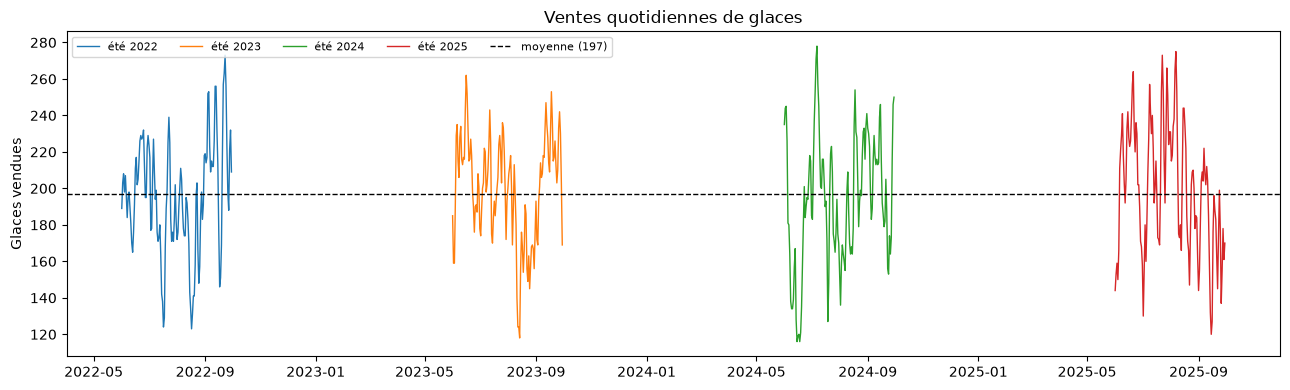

In [2]:
# Partie 1 - Le carnet de Bruno

ventes_df = pd.read_csv("data/ventes_glaces.csv", parse_dates=["date"])

print(f"{len(ventes_df)} jours d'ouverture, de {ventes_df['date'].min().date()} à {ventes_df['date'].max().date()}")
display(ventes_df.head())
display(ventes_df.groupby("saison")["ventes"].agg(["mean", "std", "min", "max"]).round(1))

plot_ventes(ventes_df)

In [3]:
N_TEST = 22

ventes = ventes_df["ventes"].to_numpy(dtype=float)
dates = ventes_df["date"]

train, test = ventes[:-N_TEST], ventes[-N_TEST:]
dates_test = dates.iloc[-N_TEST:]

In [28]:
baseline_moyenne = train.mean()
baseline_hier = np.concatenate(([train[-1]], test[:-1]))

scores = {
    "Toujours la moyenne": mae(test, baseline_moyenne),
    "Comme hier": mae(test, baseline_hier),
}
for nom, valeur in scores.items():
    print(f"{nom:22s} : {valeur:.2f} glaces d'écart en moyenne")

Toujours la moyenne    : 30.38 glaces d'écart en moyenne
Comme hier             : 19.00 glaces d'écart en moyenne


In [7]:
# Partie 2 - La mémoire d'une série
# Étape 1 : l'autocorrélation à la main

def autocorrelation(serie, lag):
    """
    Correlation of a series with itself, shifted by lag steps.

    Arguments:
    serie -- the time series, as a 1D array
    lag -- the shift, in days (lag=1 compares each day with the day before)

    Returns:
    r -- the autocorrelation coefficient, between -1 and 1
    """
    serie = np.asarray(serie, dtype=float)

    ecarts = serie - serie.mean() # (1) les écarts à la moyenne
    numerateur = (ecarts[lag:] * ecarts[:-lag]).sum() # (2) produits des écarts décalés de lag
    denominateur = (ecarts ** 2).sum() # (3) la variance totale
    r = numerateur / denominateur

    return r

In [8]:
ventes_2025 = ventes_df.loc[ventes_df["saison"] == 2025, "ventes"].to_numpy(dtype=float)

for lag in range(1, 5):
    print(f"autocorrélation à {lag} jour(s) : {autocorrelation(ventes_2025, lag):+.3f}")

reference = acf(ventes_2025, nlags=4)
assert abs(autocorrelation(ventes_2025, 1) - reference[1]) < 1e-9, \
    "Ton résultat devrait être identique à celui de statsmodels au retard 1"
assert abs(autocorrelation(ventes_2025, 3) - reference[3]) < 1e-9, \
    "Ton résultat devrait être identique à celui de statsmodels au retard 3"
print("\nExercice validé ! Une journée ressemble énormément à la veille (r ≈ 0.81), un peu moins à l'avant-veille.")

autocorrélation à 1 jour(s) : +0.813
autocorrélation à 2 jour(s) : +0.518
autocorrélation à 3 jour(s) : +0.319
autocorrélation à 4 jour(s) : +0.164

Exercice validé ! Une journée ressemble énormément à la veille (r ≈ 0.81), un peu moins à l'avant-veille.


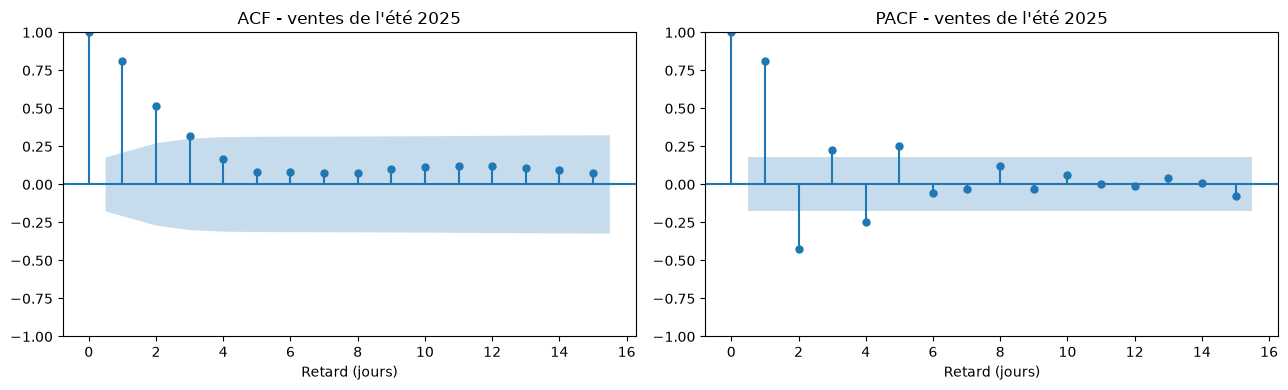

In [9]:
plot_correlogrammes(ventes_2025, lags=15, titre="- ventes de l'été 2025")

In [12]:
# Partie 3 - Le modèle MA
# Étape 2 : fabriquer une série MA à la main

def simuler_ma(mu, thetas, chocs):
    """
    Build a Moving Average series from a sequence of random shocks.

    y_t = mu + eps_t + theta_1 * eps_{t-1} + ... + theta_q * eps_{t-q}

    Arguments:
    mu -- the average level of the series
    thetas -- list of q coefficients, one per past shock
    chocs -- array of random shocks, one per time step

    Returns:
    serie -- the simulated series, of length len(chocs) - q
    """
    q = len(thetas)
    serie = []

    for t in range(q, len(chocs)):
        valeur = mu + chocs[t]  # (1) la moyenne + le choc du jour
        for i, theta in enumerate(thetas, start=1):
            valeur += theta * chocs[t - i]  # (2) l'écho des chocs passés
        serie.append(valeur)  # (3)

    return np.array(serie)



In [13]:
chocs_test = np.array([0.0, 10.0, 0.0, 0.0, 0.0])
print("Un seul choc de +10 au jour 1, avec theta = [0.8, 0.4] :")
print(simuler_ma(200, [0.8, 0.4], chocs_test), "  <- l'écho s'éteint en 2 jours")

chocs = np.random.normal(0, 15, 4000)
simulee = simuler_ma(200, [0.5], chocs)
print(f"\nMA(1) simulé avec theta=0.5 : autocorrélation au retard 1 = {autocorrelation(simulee, 1):.3f}")
print(f"                              valeur théorique theta/(1+theta^2) = {0.5 / 1.25:.3f}")
print(f"                              autocorrélation au retard 2 = {autocorrelation(simulee, 2):+.3f} (nulle, comme prévu)")

assert len(simuler_ma(200, [0.8, 0.4], chocs_test)) == 3, "La série doit être plus courte que les chocs de q valeurs"
assert abs(autocorrelation(simulee, 1) - 0.4) < 0.03, "Un MA(1) de theta=0.5 doit donner r1 proche de 0.40"
assert abs(autocorrelation(simulee, 2)) < 0.03, "Un MA(1) n'a aucune mémoire au-delà du retard 1"
print("\nExercice validé ! Un MA(q) oublie tout après exactement q jours.")

Un seul choc de +10 au jour 1, avec theta = [0.8, 0.4] :
[208. 204. 200.]   <- l'écho s'éteint en 2 jours

MA(1) simulé avec theta=0.5 : autocorrélation au retard 1 = 0.379
                              valeur théorique theta/(1+theta^2) = 0.400
                              autocorrélation au retard 2 = -0.012 (nulle, comme prévu)

Exercice validé ! Un MA(q) oublie tout après exactement q jours.


In [14]:
# Étape 3 : ajuster le MA aux ventes de Bruno

train_2025 = ventes_2025[:-N_TEST]   # la saison 2025, sans les 22 derniers jours

resultat_ma = ARIMA(train_2025, order=(0, 0, 3), trend="c").fit() # MA(3) : 0 terme AR, 0 différenciation, 3 termes MA

print(f"mu estimé : {resultat_ma.params[0]:.1f} glaces par jour")
for i in range(1, 4):
    print(f"theta_{i}   : {resultat_ma.params[i]:+.3f}")
print(f"AIC       : {resultat_ma.aic:.1f}")

assert len(resultat_ma.params) == 5, "On attend 5 paramètres : la constante, 3 thetas, et la variance du bruit"
print("\nExercice validé ! L'écho d'une bonne journée est fort le lendemain, puis s'estompe.")



/home/tolojanaharyjeanerico/machine-learning-practice/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


mu estimé : 205.3 glaces par jour
theta_1   : +1.526
theta_2   : +0.784
theta_3   : +0.089
AIC       : 850.9

Exercice validé ! L'écho d'une bonne journée est fort le lendemain, puis s'estompe.


,modèle,erreur moyenne (glaces/jour)
0,"MA(3), saison 2025 seule",16.48
1,Comme hier,21.17
2,Toujours la moyenne,29.57


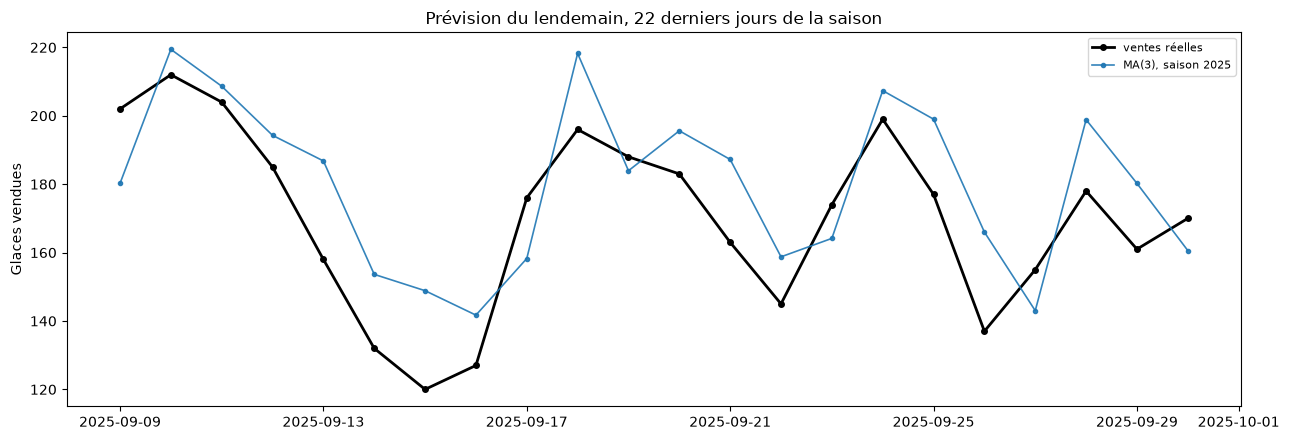

In [15]:
prev_ma_2025 = prevision_1_jour(resultat_ma, ventes_2025, N_TEST)
scores["MA(3), saison 2025 seule"] = mae(test, prev_ma_2025)

display(tableau_des_scores(scores))
plot_previsions(dates_test, test, {"MA(3), saison 2025": prev_ma_2025},
                titre="Prévision du lendemain, 22 derniers jours de la saison")

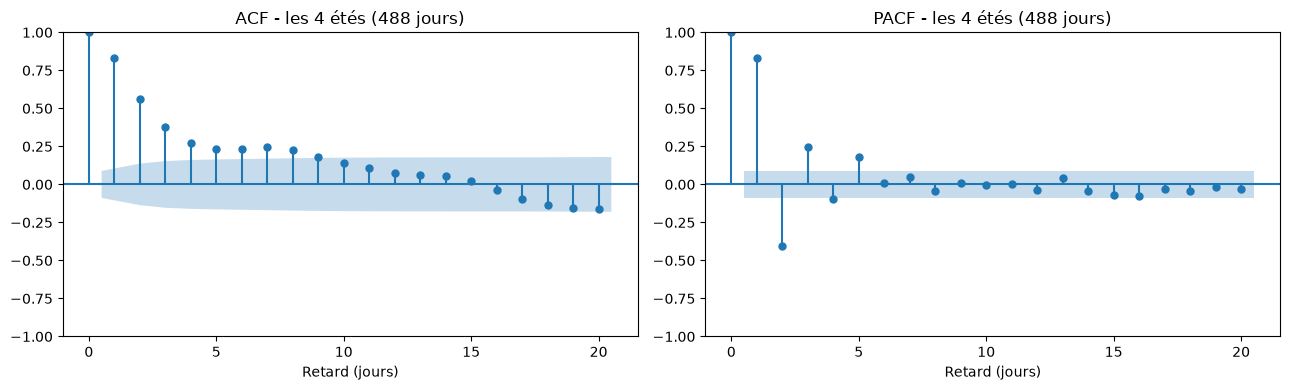

Autocorrélations, saison 2025 seule (122 jours) puis 4 étés (488 jours) :
  retard  1 : +0.813   vs   +0.828
  retard  2 : +0.518   vs   +0.559
  retard  3 : +0.319   vs   +0.378
  retard  5 : +0.081   vs   +0.231
  retard  7 : +0.077   vs   +0.243
  retard  9 : +0.103   vs   +0.181


In [16]:
# Partie 4 - Le carton du grenier : place à l'ARMA

plot_correlogrammes(ventes, lags=20, titre="- les 4 étés (488 jours)")

print("Autocorrélations, saison 2025 seule (122 jours) puis 4 étés (488 jours) :")
for lag in [1, 2, 3, 5, 7, 9]:
    print(f"  retard {lag:2d} : {autocorrelation(ventes_2025, lag):+.3f}   vs   {autocorrelation(ventes, lag):+.3f}")


In [17]:
# Étape 4 : le modèle ARMA

resultat_arma =  ARIMA(train_2025, order=(1, 0, 1), trend="c").fit() # ARMA(1,1) : 1 terme AR, 1 terme MA

print(f"mu  : {resultat_arma.params[0]:.1f} glaces par jour")
print(f"phi : {resultat_arma.params[1]:+.3f}   <- l'inertie (AR)")
print(f"theta : {resultat_arma.params[2]:+.3f}   <- l'écho des surprises (MA)")

resultat_ma_complet = ARIMA(train, order=(0, 0, 3), trend="c").fit()   # le MA(3), réentraîné sur tout l'historique
print(f"\nAIC MA(3)     : {resultat_ma_complet.aic:.1f}  ({len(resultat_ma_complet.params) - 2} coefficients)")
print(f"AIC ARMA(1,1) : {resultat_arma.aic:.1f}  ({len(resultat_arma.params) - 2} coefficients)")

assert resultat_arma.aic < resultat_ma_complet.aic, \
    "L'ARMA devrait obtenir un meilleur AIC (plus bas) que le MA(3)"
print("\nExercice validé ! Moins de coefficients, et pourtant un meilleur score.")

mu  : 204.5 glaces par jour
phi : +0.659   <- l'inertie (AR)
theta : +0.762   <- l'écho des surprises (MA)


/home/tolojanaharyjeanerico/machine-learning-practice/.venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params



AIC MA(3)     : 3945.3  (3 coefficients)
AIC ARMA(1,1) : 846.5  (2 coefficients)

Exercice validé ! Moins de coefficients, et pourtant un meilleur score.


In [18]:
for nom, resultat in [("MA(3)", resultat_ma_complet), ("ARMA(1,1)", resultat_arma)]:
    p = acorr_ljungbox(resultat.resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    verdict = "bruit pur, rien oublié" if p > 0.05 else "il reste de la structure non captée !"
    print(f"{nom:10s} Ljung-Box p = {p:.3f}   -> {verdict}")

MA(3)      Ljung-Box p = 0.000   -> il reste de la structure non captée !
ARMA(1,1)  Ljung-Box p = 0.204   -> bruit pur, rien oublié


,modèle,erreur moyenne (glaces/jour)
0,"ARMA(1,1), 4 étés",14.94
1,"MA(3), 4 étés",16.27
2,Comme hier,19.00
3,Toujours la moyenne,30.38


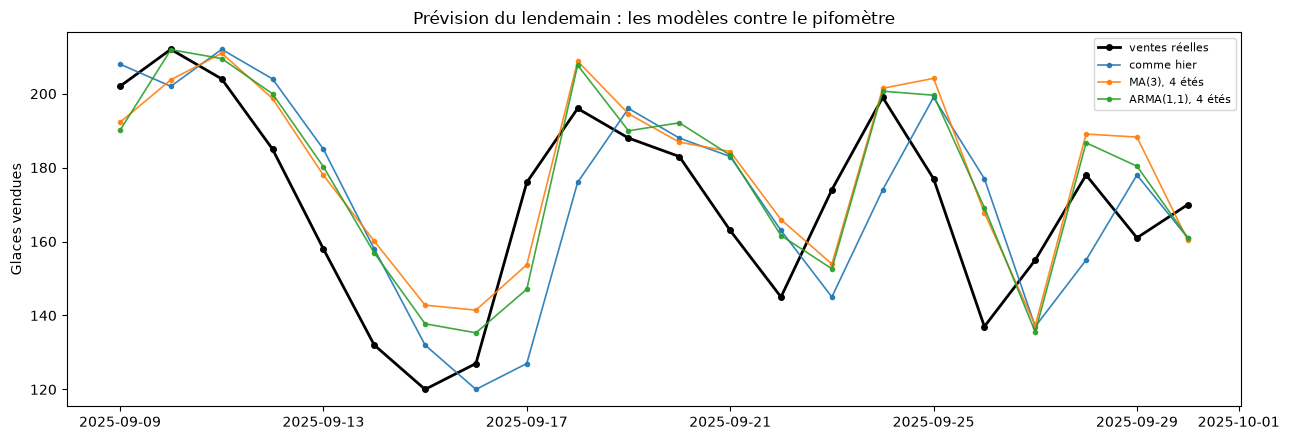

In [29]:
scores["MA(3), 4 étés"] = mae(test, prevision_1_jour(resultat_ma_complet, ventes, N_TEST))
scores["ARMA(1,1), 4 étés"] = mae(test, prevision_1_jour(resultat_arma, ventes, N_TEST))

display(tableau_des_scores(scores))

plot_previsions(dates_test, test,
                {"comme hier": baseline_hier,
                 "MA(3), 4 étés": prevision_1_jour(resultat_ma_complet, ventes, N_TEST),
                 "ARMA(1,1), 4 étés": prevision_1_jour(resultat_arma, ventes, N_TEST)},
                titre="Prévision du lendemain : les modèles contre le pifomètre")

In [32]:
# Partie 5 - La semaine de Bruno
# Étape 5 : prévoir les 7 prochains jours

semaine_ma = resultat_ma.get_forecast(steps=7).predicted_mean # (1) le MA(3)
semaine_arma = resultat_arma.get_forecast(steps=7).predicted_mean # (2) l'ARMA(1,1)

print("jour :  ", "  ".join(f"J+{j}" for j in range(1, 8)))
print("MA(3):  ", "  ".join(f"{v:5.1f}" for v in semaine_ma))
print("ARMA :  ", "  ".join(f"{v:5.1f}" for v in semaine_arma))
print(f"\nmoyenne historique : {train.mean():.1f}")

assert len(semaine_ma) == 7 and len(semaine_arma) == 7, "On attend 7 valeurs, une par jour"
assert abs(semaine_ma[3] - semaine_ma[6]) < 0.01, \
    "Le MA(3) devrait donner exactement la même valeur du 4e au 7e jour"
assert abs(semaine_arma[3] - semaine_arma[6]) > 0.01, "L'ARMA, lui, continue d'évoluer"
print("Exercice validé !")



jour :   J+1  J+2  J+3  J+4  J+5  J+6  J+7
MA(3):   180.2  186.2  202.9  205.3  205.3  205.3  205.3
ARMA :   190.1  195.0  198.2  200.4  201.8  202.7  203.3

moyenne historique : 198.3
Exercice validé !


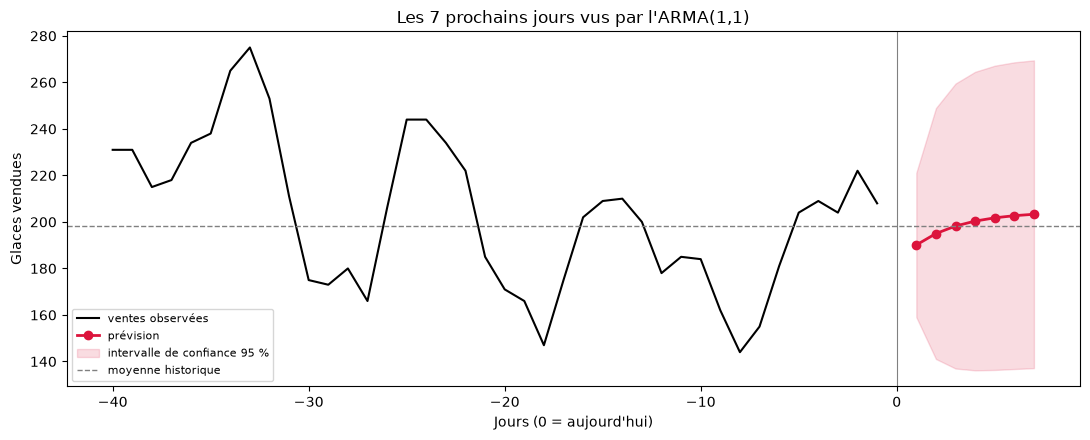

In [33]:
plot_semaine(train, resultat_arma, steps=7, titre="Les 7 prochains jours vus par l'ARMA(1,1)")